---
title: "03 Multicondition Workflow"
output: html_document
---

<!-- Generated from the companion Jupyter notebook. Open this file in RStudio and run chunks interactively. -->

# Differential Cell-Cell Communication Across Conditions

## Biological System

This tutorial uses head-and-neck squamous cell carcinoma (HNSCC) contralateral sc-multiome data as condition 1 and normal-adjacent sc-multiome data as condition 2. The workflow compares sender-ligand-receptor programs between conditions for the same receiver cell types: basal, parabasal, suprabasal, and dividing cells. Paper link: [HNSCC manuscript](../README.md#citation).

## Biological Question

Question addressed: **which sender-ligand-receptor communication programs change between contralateral and normal-adjacent tissue within the same receiver cell type?**

This question matters because the same receiver cell type can receive different signals across tissue conditions. MultiNicheNet combines expression, differential regulation, ligand activity, receptor support, and cell abundance information to prioritize condition-associated communication changes.

## Workflow Outline

This tutorial:

- Verifies that each condition has biological samples and receiver-cell abundance information.
- Builds or reuses the ContextNet ligand-target matrix.
- Runs a MultiNicheNet differential communication analysis across four epithelial subtypes.
- Interprets prioritization scores as composite evidence from expression, differential regulation, ligand activity, receptor support, and abundance.
- Renders a ccflowR Sankey river plot for the top sender-ligand-receptor-receiver programs. ccflowR is optional visualization support for path-level communication hypotheses: it turns prioritized sender -> ligand -> receptor -> receiver rows into river diagrams that make dense MultiNicheNet output easier to inspect.

## When to Use NicheNet vs MultiNicheNet

| Feature | NicheNet | MultiNicheNet |
|---------|----------|---------------|
| Function | `predict_ligand_activity_nichenet()` | `run_multinichenet()` |
| Replicates | Not required | **Required** |
| Output | Ligand activity scores (AUPR) | Sender-ligand-receptor-receiver prioritization table |
| DE method | Wilcoxon rank-sum | Pseudobulk (EdgeR) |
| `sample_col` | Not needed | **Required** |
| Use case | Single condition or no replicates | Multi-condition with replicates |

## Environment and Data Setup

Install ContextNet before starting this tutorial using the repository [installation instructions](../README.md#installation). The cells below are not installation steps. They only load packages, set public relative data paths, and define the differential communication contrast used in this notebook.



In [1]:
suppressWarnings(suppressPackageStartupMessages({
    library(ContextNet)
    library(Seurat)
    library(multinichenetr)
    library(dplyr)
    library(ggplot2)
    library(ccflowR)
}))

theme_set(theme_minimal(base_family = "sans"))


display_ccflowr_sankey <- function(sankey_plot, width, height, preview_file) {
    # GitHub leaves the interactive htmlwidget area blank, so the committed
    # tutorial displays only the ccflowR-generated static PNG preview.
    dir.create(dirname(preview_file), recursive = TRUE, showWarnings = FALSE)
    exported <- FALSE
    tryCatch({
        suppressMessages(ccflowR::sankey_save(sankey_plot, preview_file, width = width, height = height))
        exported <- file.exists(preview_file) && file.info(preview_file)[["size"]] > 0
    }, error = function(e) {
        stop(
            "Could not create the ccflowR PNG preview. Install Kaleido or webshot2: ",
            conditionMessage(e),
            call. = FALSE
        )
    })

    if (!exported) {
        stop("ccflowR PNG preview was not created.", call. = FALSE)
    }
    if (requireNamespace("IRdisplay", quietly = TRUE)) {
        IRdisplay::display_png(file = preview_file)
    } else {
        message("Static ccflowR figure written to ", preview_file)
    }
    invisible(sankey_plot)
}


In [2]:
# USER CONFIGURATION
# The HNSCC tutorial data should be placed under data/ after download from
# the ContextNet tutorial data release. Environment variables can override
# these defaults without changing the notebook source.

PROJECT_DIR <- normalizePath(getwd(), mustWork = TRUE)
if (basename(PROJECT_DIR) == "notebooks" &&
    file.exists(file.path(PROJECT_DIR, "..", "DESCRIPTION"))) {
    PROJECT_DIR <- normalizePath(file.path(PROJECT_DIR, ".."), mustWork = TRUE)
}
if (!file.exists(file.path(PROJECT_DIR, "DESCRIPTION"))) {
    stop("Run this notebook from the ContextNet repository root or from the notebooks/ directory.")
}
setwd(PROJECT_DIR)

display_path <- function(path) {
    normalized <- normalizePath(path, mustWork = FALSE)
    root <- normalizePath(PROJECT_DIR, mustWork = TRUE)
    if (startsWith(normalized, root)) {
        return(sub("^/", "", substring(normalized, nchar(root) + 1)))
    }
    paste0("<external>/", basename(normalized))
}

cat("Using project root:", basename(getwd()), "\n")

DATA_PATH <- file.path(PROJECT_DIR, "data")
GRN_FILE <- Sys.getenv("CONTEXTNET_TUTORIAL03_GRN", unset = file.path(DATA_PATH, "gene_x_tf.csv"))
SEURAT_FILE <- Sys.getenv("CONTEXTNET_TUTORIAL_SEURAT", unset = file.path(DATA_PATH, "seurat_obj.rds"))
NICHENET_DB <- Sys.getenv("CONTEXTNET_NICHENET_DB", unset = DATA_PATH)
PRECOMPUTED_MULTINICHENET <- Sys.getenv(
    "CONTEXTNET_TUTORIAL03_RESULT",
    unset = file.path(DATA_PATH, "cache", "tutorial-03-outputs", "multinichenet_result.rds")
)
CELLTYPE_COLORS_FILE <- Sys.getenv("CONTEXTNET_CELLTYPE_COLORS", unset = file.path(DATA_PATH, "celltype_colors.rds"))
USE_PRECOMPUTED_MULTINICHENET <- tolower(Sys.getenv(
    "CONTEXTNET_USE_PRECOMPUTED_MULTINICHENET",
    unset = "true"
)) %in% c("true", "1", "yes")

# Repo-local derived outputs. The cache name is specific to this C/N analysis.
CACHE_DIR <- file.path(DATA_PATH, "cache")
NETWORK_CACHE <- file.path(CACHE_DIR, "contextnet_network_naf.rds")
OUTPUT_DIR <- file.path(CACHE_DIR, "tutorial-03-outputs")

# Analysis parameters: replicate-aware multi-condition comparison.
RECEIVERS <- c("basal", "parabasal", "suprabasal", "dividing")
GROUP_COL <- "Fine_Cell_Types"
IDENT_COL <- "category"
IDENT_1 <- "C"
IDENT_2 <- "N"
SAMPLE_COL <- "sample"
MIN_CELLS <- 10          # Minimum cells per cell type per sample for pseudobulk support.
LOGFC_THRESHOLD <- 0.25  # Differential-expression threshold used by MultiNicheNet.
FRACTION_CUTOFF <- 0.05  # Minimum expressing fraction for ligand/receptor support.
TOP_N_TARGET <- 250      # Target genes retained per ligand for activity and target interpretation.
N_CORES <- as.integer(Sys.getenv("CONTEXTNET_MN_N_CORES", unset = "1"))

missing_inputs <- c(GRN_FILE, SEURAT_FILE)[!file.exists(c(GRN_FILE, SEURAT_FILE))]
if (length(missing_inputs) > 0 || !dir.exists(NICHENET_DB)) {
    stop("Missing HNSCC tutorial data. Download the tutorial files into data/ or set CONTEXTNET_TUTORIAL03_GRN, CONTEXTNET_TUTORIAL_SEURAT, and CONTEXTNET_NICHENET_DB.")
}
stopifnot(requireNamespace("ccflowR", quietly = TRUE))
cat("GRN file:", display_path(GRN_FILE), "\n")
cat("Seurat file:", display_path(SEURAT_FILE), "\n")
cat("NicheNet DB:", display_path(NICHENET_DB), "\n")
cat("Precomputed MultiNicheNet result:", display_path(PRECOMPUTED_MULTINICHENET), "\n")


cat("Use precomputed MultiNicheNet result:", USE_PRECOMPUTED_MULTINICHENET, "\n")


Using project root: ContextNet 


GRN file: data/gene_x_tf.csv 


Seurat file: data/seurat_obj.rds 


NicheNet DB: data 


Precomputed MultiNicheNet result: data/cache/tutorial-03-outputs/multinichenet_result.rds 


Use precomputed MultiNicheNet result: TRUE 



## Step 1: Load and Explore Data

MultiNicheNet requires biological replicates. Verify that each condition has multiple samples.



In [3]:
seurat_obj <- readRDS(SEURAT_FILE)
cat("Loaded Seurat object\n")
cat("  Cells:", ncol(seurat_obj), "\n")
cat("  Genes:", nrow(seurat_obj), "\n")
cat("  Metadata columns:", ncol(seurat_obj[[]]), "\n")


Loaded Seurat object


  Cells: 145769 


  Genes: 16524 


  Metadata columns: 23 


In [4]:
# Verify replicates: each condition must have multiple samples
table(seurat_obj$category, seurat_obj[[SAMPLE_COL]][, 1])


   
    Pt32C Pt32M Pt33C Pt33M Pt44C Pt44N Pt44M Pt45C Pt45N Pt45T Pt50C Pt50N
  C  6182     0  2498     0  6444     0     0  6534     0     0   942     0
  M     0  9236     0  3959     0     0  6860     0     0     0     0     0
  N     0     0     0     0     0 14515     0     0  4210     0     0  2239
  T     0     0     0     0     0     0     0     0     0 16104     0     0
   
    Pt50T Pt51C Pt51N Pt51M Pt56C Pt56N Pt56T Pt59C Pt59N Pt59T
  C     0  5439     0     0  6071     0     0  4716     0     0
  M     0     0     0  6596     0     0     0     0     0     0
  N     0     0  5580     0     0  1055     0     0  8175     0
  T  7463     0     0     0     0     0  8201     0     0 12750


### Replicate Design Check

MultiNicheNet treats samples, not cells, as the experimental units. The table above should show multiple samples per condition; otherwise the workflow cannot support replicate-aware differential communication claims.



In [5]:
# Subset to conditions of interest.
seurat_cn <- subset(seurat_obj, subset = category %in% c(IDENT_1, IDENT_2))
seurat_cn[[SAMPLE_COL]] <- droplevels(as.factor(seurat_cn[[SAMPLE_COL]][, 1]))
seurat_cn[[IDENT_COL]] <- droplevels(as.factor(seurat_cn[[IDENT_COL]][, 1]))
seurat_cn[[GROUP_COL]] <- droplevels(as.factor(seurat_cn[[GROUP_COL]][, 1]))

cat("Cells:", ncol(seurat_cn), "\n")
table(seurat_cn[[IDENT_COL]][, 1])


Cells: 74600 



    C     N 
38826 35774 

In [6]:
celltype_counts <- sort(table(seurat_cn[[GROUP_COL]][, 1]), decreasing = TRUE)
print(celltype_counts)



        basal   Endothelial        T Cell    suprabasal Myofibroblast 
        16039         13538         13031         12471          5103 
    parabasal    Fibroblast      dividing       Myeloid transitioning 
         3282          3109          2971          2698          1816 
   Melanocyte        B Cell        Muscle      Neuronal 
          234           151           120            37 



### Sample-Level Abundance Check

MultiNicheNet uses samples as the replicate unit. An epithelial subtype can have many cells overall but still be weakly supported if it appears in too few samples or is dominated by one condition. Check receiver abundance by condition and sample before interpreting differential communication programs.



In [7]:
abundance_by_sample <- as.data.frame(table(
    condition = seurat_cn[[IDENT_COL]][, 1],
    sample = seurat_cn[[SAMPLE_COL]][, 1],
    cell_type = seurat_cn[[GROUP_COL]][, 1]
))
abundance_by_sample <- abundance_by_sample[abundance_by_sample$Freq > 0, ]

receiver_abundance <- abundance_by_sample %>%
    filter(cell_type %in% RECEIVERS) %>%
    group_by(condition, sample, cell_type) %>%
    summarize(cells = sum(Freq), .groups = "drop")

receiver_abundance_summary <- receiver_abundance %>%
    group_by(condition, cell_type) %>%
    summarize(
        n_samples = dplyr::n_distinct(sample),
        min_cells = min(cells),
        median_cells = stats::median(cells),
        max_cells = max(cells),
        .groups = "drop"
    ) %>%
    arrange(cell_type, condition)

receiver_abundance_summary


condition,cell_type,n_samples,min_cells,median_cells,max_cells
<fct>,<fct>,<int>,<int>,<dbl>,<int>
C,basal,8,117,1155.0,1915
N,basal,6,24,690.5,4780
C,dividing,8,21,217.0,672
N,dividing,6,9,159.5,281
C,parabasal,8,26,252.5,669
N,parabasal,6,1,96.5,619
C,suprabasal,8,115,784.5,1810
N,suprabasal,6,18,740.0,2391


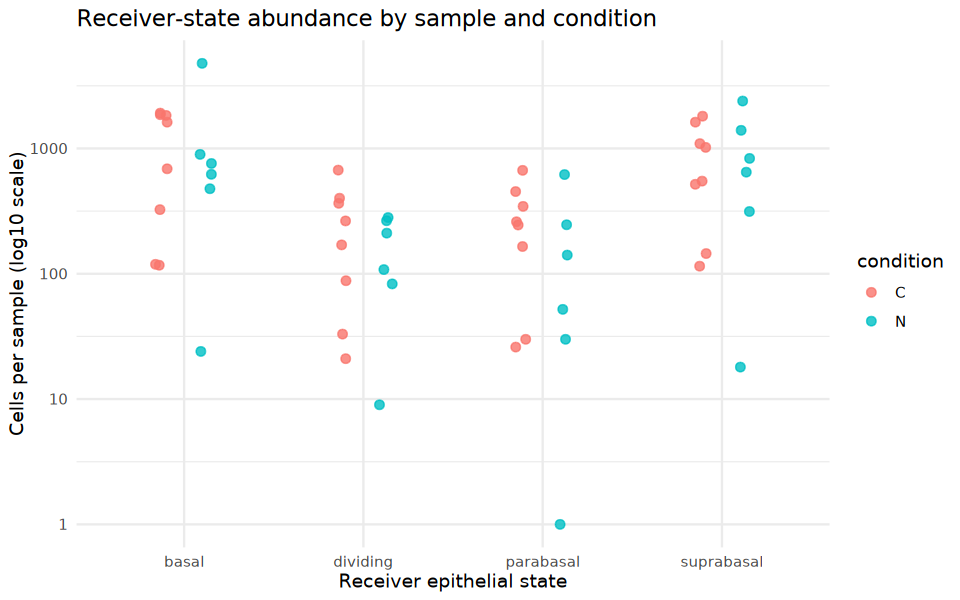

In [8]:
options(repr.plot.width = 8, repr.plot.height = 5)

ggplot(receiver_abundance, aes(x = cell_type, y = cells, color = condition)) +
    geom_point(position = position_jitterdodge(jitter.width = 0.15, dodge.width = 0.5), size = 2, alpha = 0.8) +
    scale_y_log10() +
    labs(
        x = "Receiver epithelial state",
        y = "Cells per sample (log10 scale)",
        title = "Receiver-state abundance by sample and condition"
    )



### Sender and Receiver Universe

The analysis tests every observed cell type as a potential sender and focuses receiver interpretation on four epithelial subtypes: basal, parabasal, suprabasal, and dividing. Low-abundance cell types are kept in the candidate universe here; MultiNicheNet applies the `MIN_CELLS` sample-level filter during pseudobulk analysis.



In [9]:
all_celltypes <- as.character(unique(seurat_cn@meta.data[[GROUP_COL]]))

sender_receiver_pairs <- list()
for (sender in all_celltypes) {
    for (receiver in RECEIVERS) {
        sender_receiver_pairs <- c(sender_receiver_pairs, list(c(sender, receiver)))
    }
}

cat("Cell types:", paste(sort(all_celltypes), collapse = ", "), "\n")
cat("Sender-receiver pairs:", length(sender_receiver_pairs), "\n")
cat("Receivers:", paste(RECEIVERS, collapse = ", "), "\n")
cat("Comparison:", IDENT_1, "vs", IDENT_2, "\n")


Cell types: B Cell, basal, dividing, Endothelial, Fibroblast, Melanocyte, Muscle, Myeloid, Myofibroblast, Neuronal, parabasal, suprabasal, T Cell, transitioning 


Sender-receiver pairs: 56 


Receivers: basal, parabasal, suprabasal, dividing 


Comparison: C vs N 



## Step 2: Use the Matching NAF ContextNet Matrix

The saved HNSCC MultiNicheNet result is loaded by default, so the notebook does not rebuild the large ligand-target matrix unless rerun is requested by setting `CONTEXTNET_USE_PRECOMPUTED_MULTINICHENET=false`.

This matters biologically: the C/N matrix used for replicate-aware differential communication is not interchangeable with the contralateral-only matrix from Tutorial 02 because the two notebooks ask different questions.



In [10]:
# The saved reference MultiNicheNet object already comes from a ContextNet LTM
# built with the NAF-remade GRN. Rebuild the network only when rerunning MN.
if (USE_PRECOMPUTED_MULTINICHENET && file.exists(PRECOMPUTED_MULTINICHENET)) {
    network <- NULL
    ltm <- NULL
    cat("Precomputed MultiNicheNet result found; skipping network rebuild.\n")
    cat("Expected ContextNet ligand-target matrix from the HNSCC tutorial data: 25311 targets x 1226 ligands\n")
} else {
    network_loaded <- FALSE
    if (file.exists(NETWORK_CACHE)) {
        network <- readRDS(NETWORK_CACHE)
        ltm <- ligand_target_matrix(network)
        network_loaded <- length(targets(network)) == 25311
        if (network_loaded) {
            cat("Loaded cached ContextNetwork from:", display_path(NETWORK_CACHE), "\n")
        } else {
            cat("Cached network dimensions differ from the HNSCC tutorial matrix; rebuilding.\n")
            rm(network, ltm)
        }
    }

    if (!network_loaded) {
        grn <- import_grn(GRN_FILE, format = "pipeline")
        if (length(targets(grn)) != 12513) {
            warning("GRN dimensions differ from the HNSCC tutorial data; MultiNicheNet rankings and figures may differ.")
        }
        network <- integrate_networks(
            grn,
            nichenet_database = NICHENET_DB,
            mode = "replace"  # use the HNSCC GRN as the regulatory layer
        )
        if (!dir.exists(CACHE_DIR)) dir.create(CACHE_DIR, recursive = TRUE)
        saveRDS(network, NETWORK_CACHE)
        ltm <- ligand_target_matrix(network)
    }

    cat("ContextNetwork ready\n")
    cat("  Ligands:", length(ligands(network)), "\n")
    cat("  Target genes:", length(targets(network)), "\n")
    cat("  Ligand-target matrix:", nrow(ltm), "targets x", ncol(ltm), "ligands\n")
}


Precomputed MultiNicheNet result found; skipping network rebuild.
Expected ContextNet ligand-target matrix from the HNSCC tutorial data: 25311 targets x 1226 ligands



## Step 3: Run or Load the Reference MultiNicheNet Analysis

The HNSCC tutorial result uses separate epithelial subtypes, with dividing retained as its own receiver. To keep the tutorial output stable and fast for review, this notebook loads that saved result when it is available. If `CONTEXTNET_USE_PRECOMPUTED_MULTINICHENET=false`, or if the saved object is absent, the same `run_multinichenet()` call is executed from the inputs above.



In [11]:
if (USE_PRECOMPUTED_MULTINICHENET && file.exists(PRECOMPUTED_MULTINICHENET)) {
    pkg_mn_ctx <- readRDS(PRECOMPUTED_MULTINICHENET)
    cat("Loaded precomputed MultiNicheNet result:", display_path(PRECOMPUTED_MULTINICHENET), "\n")
} else {
    cat("Running MultiNicheNet from the reference inputs. This can take 20-40 minutes.\n")
    pkg_mn_ctx <- suppressWarnings(run_multinichenet(
        object = seurat_cn,
        network = network,
        sender_receiver_pairs = sender_receiver_pairs,
        condition_col = IDENT_COL,
        contrast = c(condition_oi = IDENT_1, condition_ref = IDENT_2),
        sample_col = SAMPLE_COL,
        group_col = GROUP_COL,
        min_cells = MIN_CELLS,
        logfc_threshold = LOGFC_THRESHOLD,
        fraction_cutoff = FRACTION_CUTOFF,
        top_n_target = TOP_N_TARGET,  # targets retained per ligand in the differential analysis
        nichenet_database = NICHENET_DB,
        n_cores = N_CORES,
        verbose = TRUE
    ))
}

ctx_prio <- pkg_mn_ctx$multinichenet_output$prioritization_tables$group_prioritization_tbl
cat("Prioritization table:", nrow(ctx_prio), "rows\n")


Loaded precomputed MultiNicheNet result: data/cache/tutorial-03-outputs/multinichenet_result.rds 


Prioritization table: 67796 rows



## Step 4: Explore Prioritized Communication Programs

MultiNicheNet returns a prioritization table with composite scores integrating ligand and receptor expression, differential expression, ligand activity, and abundance-aware sender-receiver context. Results span all sender-receiver pairs and both contrast directions (`C` and `N`).

`ctx_prio` is the main interpretation table. Each row is a sender-ligand-receptor-receiver program in one condition group. The `prioritization_score` is a composite score, so a high-ranked row is a hypothesis to inspect, not proof that one molecular mechanism is causal.



In [12]:
cat("Prioritization rows:", nrow(ctx_prio), "\n")
cat("Groups:", paste(sort(unique(ctx_prio$group)), collapse = ", "), "\n")
cat("Senders:", paste(sort(unique(ctx_prio$sender)), collapse = ", "), "\n")
cat("Receivers:", paste(sort(unique(ctx_prio$receiver)), collapse = ", "), "\n")
cat("Unique ligands:", dplyr::n_distinct(ctx_prio$ligand), "\n")
cat("Unique receptors:", dplyr::n_distinct(ctx_prio$receptor), "\n")

ctx_prio %>%
    arrange(desc(prioritization_score)) %>%
    select(group, sender, receiver, ligand, receptor, prioritization_score) %>%
    head(10)


Prioritization rows: 67796 


Groups: C, N 


Senders: basal, dividing, Endothelial, Fibroblast, Melanocyte, Myeloid, Myofibroblast, parabasal, suprabasal, T Cell, transitioning 


Receivers: basal, dividing, parabasal, suprabasal 


Unique ligands: 492 


Unique receptors: 351 


,group,sender,receiver,ligand,receptor,prioritization_score
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,C,Fibroblast,parabasal,TIMP1,CD63,0.9501686
2,C,Myeloid,parabasal,ALCAM,NRP1,0.9492240
3,C,Fibroblast,basal,TIMP1,CD63,0.9256878
4,C,Myeloid,basal,ALCAM,NRP1,0.9220948
5,N,Myofibroblast,basal,SEMA6D,PLXNA1,0.9080250
6,N,Fibroblast,basal,IGF1,INSR,0.8982123
7,C,Fibroblast,dividing,CALR,TAP1,0.8970320
8,C,Myeloid,parabasal,TIMP1,CD63,0.8957722
9,N,transitioning,parabasal,CDCP1,EGFR,0.8917696


In [13]:
ligand_summary <- ctx_prio %>%
    group_by(ligand) %>%
    summarize(
        prioritization_score = max(prioritization_score, na.rm = TRUE),
        n_rows = dplyr::n(),
        n_senders = dplyr::n_distinct(sender),
        n_receivers = dplyr::n_distinct(receiver),
        groups = paste(sort(unique(group)), collapse = ", "),
        .groups = "drop"
    ) %>%
    arrange(desc(prioritization_score))

head(ligand_summary, 15)


ligand,prioritization_score,n_rows,n_senders,n_receivers,groups
<chr>,<dbl>,<int>,<int>,<int>,<chr>
TIMP1,0.9501686,176,11,4,"C, N"
ALCAM,0.9492240,264,11,4,"C, N"
SEMA6D,0.9080250,32,4,4,"C, N"
IGF1,0.8982123,80,2,4,"C, N"
CALR,0.8970320,440,11,4,"C, N"
CDCP1,0.8917696,48,6,4,"C, N"
LGALS9,0.8906573,136,4,4,"C, N"
WNT5B,0.8897335,584,9,4,"C, N"
F13A1,0.8842376,48,3,4,"C, N"



### Reading the MultiNicheNet Table

For this workflow, a high-ranked row should be read as a **condition-associated differential communication program**. The score is not only ligand activity; it combines ligand/receptor expression, differential regulation, target activity, and sender-receiver context. Use the table to identify which component supports the path before making a biological claim.



In [14]:
head(ligand_summary$ligand, 30)


[1] "TIMP1""ALCAM""SEMA6D""IGF1""CALR""CDCP1"   
 [7] "LGALS9""WNT5B""F13A1""PLAU""TNXB""CEACAM1" 
[13] "NRG1""EFNA5""HMGB1""CEACAM5""KIRREL1""EPGN"    
[19] "SERPING1""ECM1""FGF2""CCN2""EDN1""WNT5A"   
[25] "CD320""TGFA""TNC""FN1""DLK2""DCN"

In [15]:
ctx_prio %>%
    arrange(desc(prioritization_score)) %>%
    select(group, sender, receiver, ligand, receptor, prioritization_score,
           scaled_lfc_ligand, scaled_lfc_receptor, max_scaled_activity) %>%
    head(20)


,group,sender,receiver,ligand,receptor,prioritization_score,scaled_lfc_ligand,scaled_lfc_receptor,max_scaled_activity
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,C,Fibroblast,parabasal,TIMP1,CD63,0.9501686,0.9341675,0.9171573,0.8281201
2,C,Myeloid,parabasal,ALCAM,NRP1,0.9492240,0.8573765,0.9604710,0.8419345
3,C,Fibroblast,basal,TIMP1,CD63,0.9256878,0.9341675,0.9234651,0.7407116
4,C,Myeloid,basal,ALCAM,NRP1,0.9220948,0.8573765,0.8315812,0.9589816
5,N,Myofibroblast,basal,SEMA6D,PLXNA1,0.9080250,0.9721950,0.5916737,1.0010000
6,N,Fibroblast,basal,IGF1,INSR,0.8982123,0.9515047,0.8921362,0.4964235
7,C,Fibroblast,dividing,CALR,TAP1,0.8970320,0.8921328,0.7697645,0.7074042
8,C,Myeloid,parabasal,TIMP1,CD63,0.8957722,0.7913804,0.9171573,0.8281201
9,N,transitioning,parabasal,CDCP1,EGFR,0.8917696,0.8075728,0.8195963,0.7535021


In [16]:
list(
    condition_col = IDENT_COL,
    contrast = c(condition_oi = IDENT_1, condition_ref = IDENT_2),
    sample_col = SAMPLE_COL,
    group_col = GROUP_COL,
    receivers = RECEIVERS,
    sender_receiver_pairs = length(sender_receiver_pairs),
    min_cells = MIN_CELLS,
    logfc_threshold = LOGFC_THRESHOLD,
    fraction_cutoff = FRACTION_CUTOFF,
    top_n_target = TOP_N_TARGET,  # targets retained per ligand in this run
    n_cores = N_CORES,
    used_precomputed_result = USE_PRECOMPUTED_MULTINICHENET && file.exists(PRECOMPUTED_MULTINICHENET)
)


$condition_col
[1] "category"

$contrast
 condition_oi condition_ref 
          "C""N" 

$sample_col
[1] "sample"

$group_col
[1] "Fine_Cell_Types"

$receivers
[1] "basal""parabasal""suprabasal""dividing"  

$sender_receiver_pairs
[1] 56

$min_cells
[1] 10

$logfc_threshold
[1] 0.25

$fraction_cutoff
[1] 0.05

$top_n_target
[1] 250

$n_cores
[1] 1

$used_precomputed_result
[1] TRUE


## Step 5: Visualize



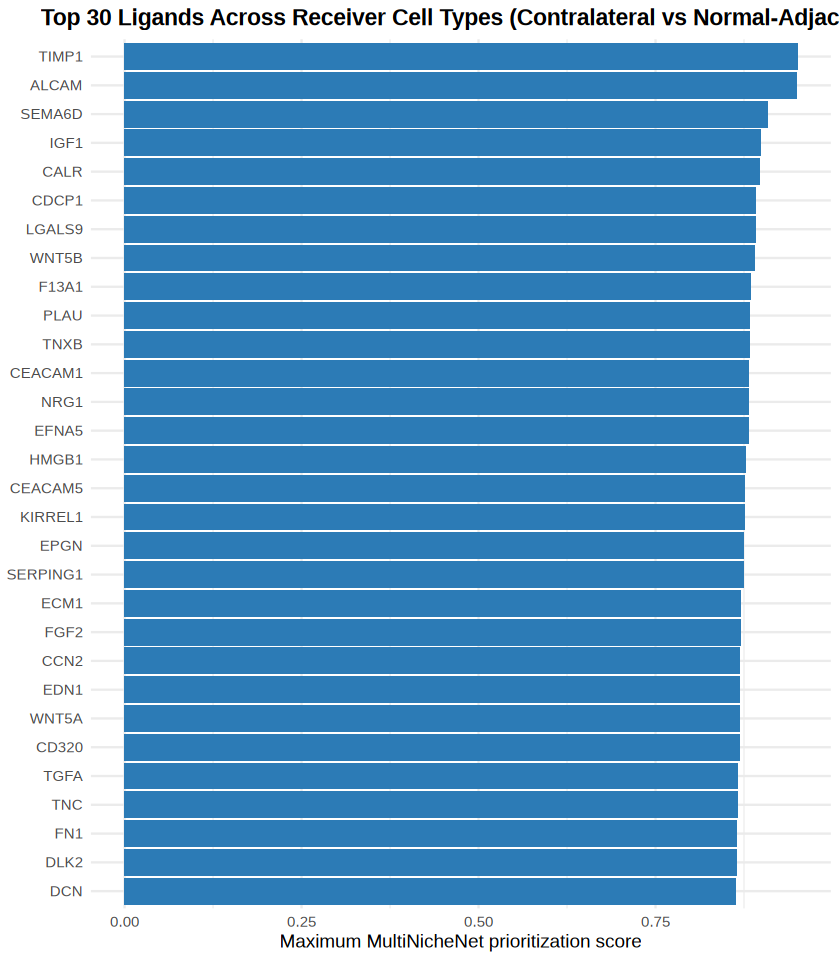

In [17]:
options(repr.plot.width = 7, repr.plot.height = 8)

top_act <- head(ligand_summary, 30)
top_act$ligand <- factor(top_act$ligand, levels = rev(top_act$ligand))

ggplot(top_act, aes(x = prioritization_score, y = ligand)) +
    geom_col(fill = "#2C7BB6") +
    labs(
        x = "Maximum MultiNicheNet prioritization score",
        y = NULL,
        title = "Top 30 Ligands Across Receiver Cell Types (Contralateral vs Normal-Adjacent)"
    ) +
    theme_minimal() +
    theme(plot.title = element_text(hjust = 0.5, face = "bold"))



**Interpretation**: This plot collapses across sender, receptor, receiver, and condition to show which ligands appear in the strongest prioritized programs. Use it as a screening view only. The row-level table and Sankey plot below are needed to see which sender and receiver support each ligand.

### Sankey River Plot with ccflowR

ccflowR is used here as an interpretability layer over the MultiNicheNet prioritization table. The graph asks: **which sender -> ligand -> receptor -> epithelial-subtype routes account for the highest-priority contralateral-versus-normal-adjacent communication programs across samples?**

The HNSCC tutorial analysis plots the top rows of `group_prioritization_tbl` directly. This preserves the same row-level evidence used in the prioritization table rather than remapping through `prepare_for_ccflowr()`.



In [18]:
subset_combined <- ctx_prio %>%
    filter(sender != "transitioning") %>%
    arrange(desc(prioritization_score)) %>%
    slice_head(n = 50) %>%
    ungroup()

cat(sprintf("Top interactions: %d rows\n", nrow(subset_combined)))
cat(sprintf("Groups: %s\n", paste(unique(subset_combined$group), collapse = ", ")))
cat(sprintf("Unique senders:   %s\n", paste(sort(unique(subset_combined$sender)), collapse = ", ")))
cat(sprintf("Unique receivers: %s\n", paste(sort(unique(subset_combined$receiver)), collapse = ", ")))
cat(sprintf("Unique ligands:   %d\n", dplyr::n_distinct(subset_combined$ligand)))
cat(sprintf("Unique receptors: %d\n", dplyr::n_distinct(subset_combined$receptor)))
print(table(subset_combined$group))

subset_combined %>%
    select(group, sender, ligand, receptor, receiver, prioritization_score) %>%
    head(10)


Top interactions: 50 rows


Groups: C, N


Unique senders:   basal, dividing, Endothelial, Fibroblast, Myeloid, Myofibroblast, parabasal, suprabasal


Unique receivers: basal, dividing, parabasal, suprabasal


Unique ligands:   28


Unique receptors: 28



 C  N 
26 24 


,group,sender,ligand,receptor,receiver,prioritization_score
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,C,Fibroblast,TIMP1,CD63,parabasal,0.9501686
2,C,Myeloid,ALCAM,NRP1,parabasal,0.9492240
3,C,Fibroblast,TIMP1,CD63,basal,0.9256878
4,C,Myeloid,ALCAM,NRP1,basal,0.9220948
5,N,Myofibroblast,SEMA6D,PLXNA1,basal,0.9080250
6,N,Fibroblast,IGF1,INSR,basal,0.8982123
7,C,Fibroblast,CALR,TAP1,dividing,0.8970320
8,C,Myeloid,TIMP1,CD63,parabasal,0.8957722
9,C,Myeloid,LGALS9,SLC1A5,parabasal,0.8906573


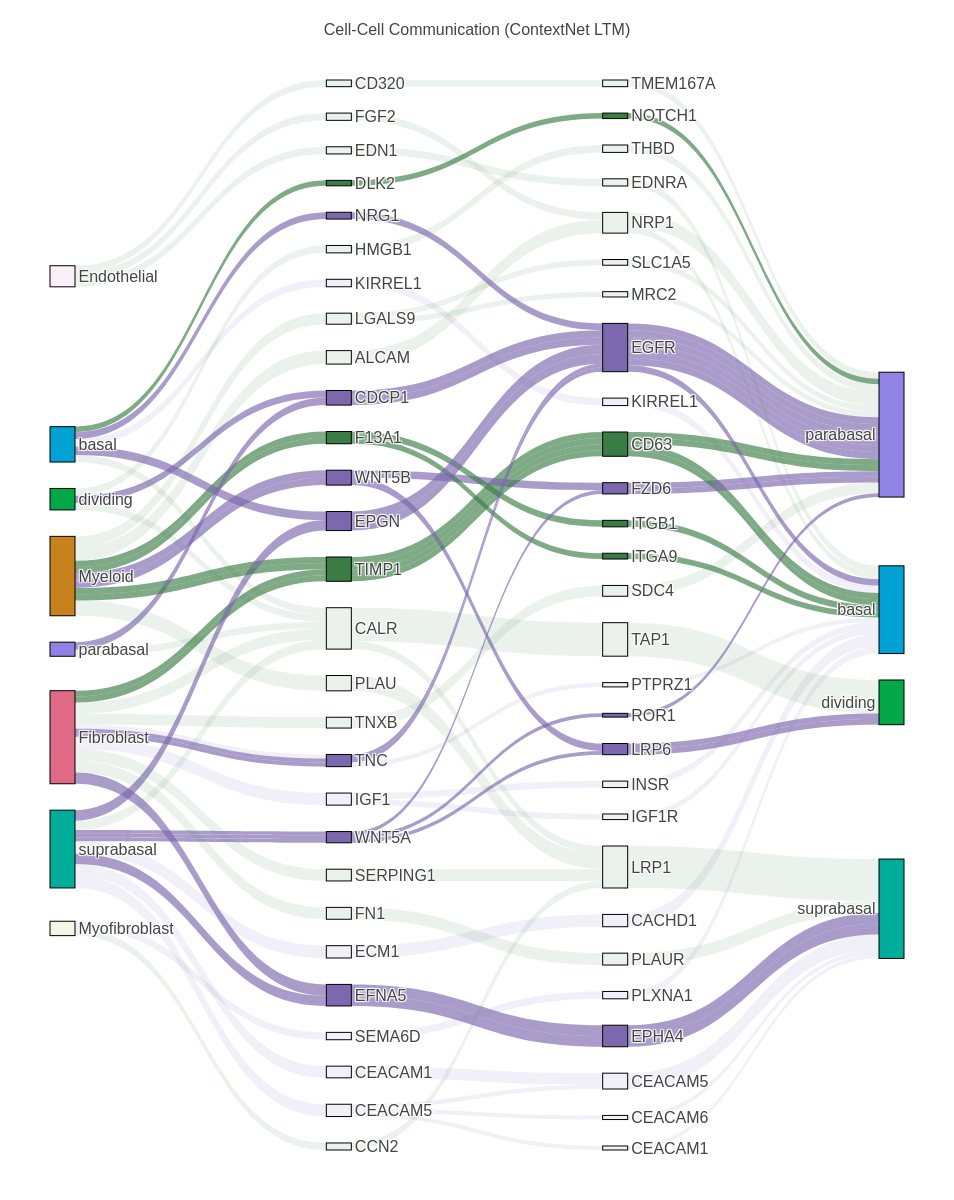

In [19]:
if (file.exists(CELLTYPE_COLORS_FILE)) {
    celltype_colors <- readRDS(CELLTYPE_COLORS_FILE)
} else {
    cell_types_in_plot <- unique(c(subset_combined$sender, subset_combined$receiver))
    palette <- grDevices::hcl.colors(length(cell_types_in_plot), palette = "Dark 3")
    celltype_colors <- stats::setNames(palette, cell_types_in_plot)
}
group_colors <- c("C" = "#3A7D44", "N" = "#7B68AE")

sankey_plot <- suppressMessages(
    ccflowR::sankey_plot(
        subset_combined,
        colors = celltype_colors,
        group_colors = group_colors,
        group_col = "group"
    ) +
        ccflowR::sankey_colors(by = "condition") +
        ccflowR::sankey_title("Cell-Cell Communication (ContextNet LTM)") +
        ccflowR::sankey_font(family = "Arial", size = 12) +
        ccflowR::sankey_layout(height = 1200, width = 954) +
        ccflowR::sankey_highlight(
            receptors = c("EGFR", "GZD6", "NOTCH1", "LRP6", "ROR1", "FZD6", "ITGA9", "ITGB1", "EPHA4", "CD63")
        )
)
display_ccflowr_sankey(
    sankey_plot,
    width = 954,
    height = 1200,
    preview_file = file.path(PROJECT_DIR, "notebooks", "figures", "03-ccflowr-sankey.png")
)



Static GitHub preview:

![Figure 4 ccflowR Sankey river plot](figures/03-ccflowr-sankey.png)

## Step 6: Save Results



In [20]:
if (!dir.exists(OUTPUT_DIR)) dir.create(OUTPUT_DIR, recursive = TRUE)
saveRDS(pkg_mn_ctx, file.path(OUTPUT_DIR, "multinichenet_result.rds"))
write.csv(ctx_prio, file.path(OUTPUT_DIR, "multinichenet_prioritization_table.csv"), row.names = FALSE)
write.csv(subset_combined, file.path(OUTPUT_DIR, "multinichenet_top50_sankey_rows.csv"), row.names = FALSE)
write.csv(receiver_abundance_summary, file.path(OUTPUT_DIR, "receiver_abundance_summary.csv"), row.names = FALSE)
cat("Saved tutorial outputs to:", OUTPUT_DIR, "\n")
list.files(OUTPUT_DIR, pattern = "\\.(rds|csv)$")


Saved tutorial outputs to:  


[1] "multinichenet_activities.csv"          
[2] "multinichenet_prioritization_table.csv"
[3] "multinichenet_result.rds"              
[4] "multinichenet_top50_sankey_rows.csv"   
[5] "receiver_abundance_summary.csv"

In [21]:
session_pkgs <- c("ContextNet", "Seurat", "nichenetr", "multinichenetr", "ggplot2", "ccflowR")
cat("R version:", R.version.string, "\n")
for (pkg in session_pkgs) {
    if (requireNamespace(pkg, quietly = TRUE)) {
        cat(pkg, "version:", as.character(utils::packageVersion(pkg)), "\n")
    }
}


R version: R version 4.4.3 (2025-02-28) 


ContextNet version: 0.1.0 
Seurat version: 5.5.0 
nichenetr version: 2.2.1.1 
multinichenetr version: 2.1.0 
ggplot2 version: 4.0.3 
ccflowR version: 0.1.0 



## Key Parameters

| Parameter | Required | Description |
|-----------|----------|-------------|
| `GRN_FILE` | Yes | C/N NAF-remade context GRN used to build the ContextNet ligand-target matrix |
| `sender_receiver_pairs` | Yes | All observed sender cell types crossed with basal, parabasal, suprabasal, and dividing receivers |
| `condition_col` / `IDENT_COL` | Yes | Metadata column for condition grouping; this tutorial uses `category` |
| `contrast` | Yes | `C` as condition of interest and `N` as reference |
| `sample_col` / `SAMPLE_COL` | **Yes** | Metadata column for sample/replicate IDs |
| `group_col` / `GROUP_COL` | Yes | Metadata column with cell type labels |
| `min_cells` / `MIN_CELLS` | Yes | Minimum cells per cell type per sample for pseudobulk support; reference value is 10 |
| `top_n_target` / `TOP_N_TARGET` | Yes | Number of target genes retained per ligand; reference value is 250 |
| `PRECOMPUTED_MULTINICHENET` | No | Saved reference run loaded by default so tutorial figures match the supplied analysis |

### MultiNicheNet Prioritization Score

The composite prioritization score integrates criteria such as ligand expression, receptor expression, ligand differential expression, receptor differential expression, ligand activity, and cell abundance. Inspect the underlying table before assigning the biological signal to one mechanism.

| Criterion | Description |
|-----------|-------------|
| `scaled_lfc_ligand` | Scaled log fold-change of ligand between conditions |
| `scaled_p_val_ligand_adapted` | Scaled significance of ligand DE |
| `scaled_lfc_receptor` | Scaled log fold-change of receptor between conditions |
| `scaled_p_val_receptor_adapted` | Scaled significance of receptor DE |
| `max_scaled_activity` | Maximum ligand activity score across target genes |
| `scaled_pb_ligand` | Scaled pseudobulk expression of ligand |
| `scaled_pb_receptor` | Scaled pseudobulk expression of receptor |
| `fraction_expressing_ligand_receptor` | Fraction of cells expressing the L-R pair |

## Using the Context-Specific Matrix with multinichenetr Directly

For custom contrasts, paired designs, additional filtering, or direct comparison between the ContextNet matrix and the default NicheNet matrix, use the ContextNet ligand-target matrix wherever MultiNicheNet expects `ligand_target_matrix`. The matrix is a standard R matrix with targets as rows and ligands as columns.



In [22]:
# The precomputed tutorial result already used a ContextNet ligand-target matrix.
# For a new native MultiNicheNet run, load the cached ContextNetwork if it exists
# or rerun Step 2 with CONTEXTNET_USE_PRECOMPUTED_MULTINICHENET=false.
context_ltm <- NULL
if (exists("network") && !is.null(network)) {
    context_ltm <- ligand_target_matrix(network)
} else if (file.exists(NETWORK_CACHE)) {
    network <- readRDS(NETWORK_CACHE)
    context_ltm <- ligand_target_matrix(network)
    cat("Loaded ContextNetwork for native MultiNicheNet reuse from:", display_path(NETWORK_CACHE), "\n")
}

if (is.null(context_ltm)) {
    message("Context-specific ligand-target matrix is not loaded in this precomputed run. Rebuild or load NETWORK_CACHE before a native MultiNicheNet rerun.")
} else {
    cat("Context-specific ligand-target matrix:", nrow(context_ltm), "targets x", ncol(context_ltm), "ligands\n")
}


Context-specific ligand-target matrix is not loaded in this precomputed run. Rebuild or load NETWORK_CACHE before a native MultiNicheNet rerun.




In a native MultiNicheNet call, the key change is the `ligand_target_matrix = context_ltm` argument. The ligand-receptor network can stay as the NicheNet ligand-receptor network, while the ligand-target matrix is replaced by the ContextNet matrix:

```r
mn_native <- multinichenetr::multi_nichenet_analysis(
    sce = sce,
    celltype_id = GROUP_COL,
    sample_id = SAMPLE_COL,
    group_id = IDENT_COL,
    batches = NA,
    covariates = NA,
    lr_network = lr_network,
    ligand_target_matrix = context_ltm,
    contrasts_oi = contrasts_oi,
    contrast_tbl = contrast_tbl,
    senders_oi = senders_oi,
    receivers_oi = RECEIVERS
)
```

The saved `pkg_mn_ctx` object can still be used for native MultiNicheNet plots because the prioritization tables were produced from the ContextNet matrix. The static circos plot summarizes sender-ligand-receptor-receiver links from the prioritization table and is saved as a GitHub-renderable PNG.



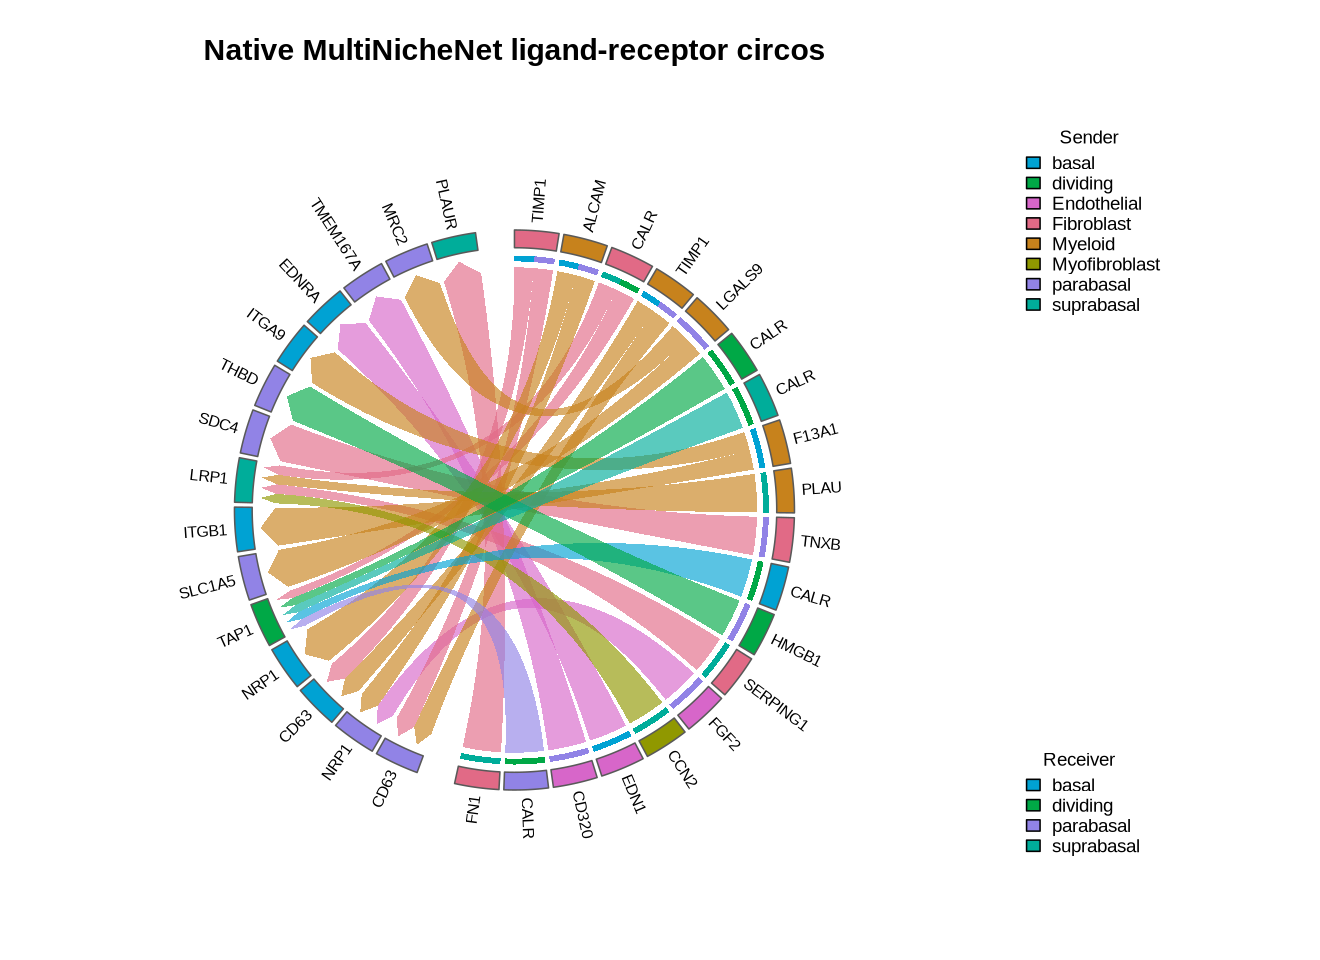

In [23]:
if (requireNamespace("circlize", quietly = TRUE)) {
    options(repr.plot.width = 11, repr.plot.height = 8)

    native_mn_tbl <- ctx_prio %>%
        filter(group == IDENT_1) %>%
        arrange(desc(prioritization_score)) %>%
        slice_head(n = 25) %>%
        ungroup()

    native_senders <- sort(unique(native_mn_tbl$sender))
    native_receivers <- sort(unique(native_mn_tbl$receiver))
    native_sender_colors <- celltype_colors[native_senders]
    native_receiver_colors <- celltype_colors[native_receivers]
    if (any(is.na(native_sender_colors))) {
        native_sender_colors[is.na(native_sender_colors)] <- grDevices::hcl.colors(sum(is.na(native_sender_colors)), "Dark 3")
    }
    if (any(is.na(native_receiver_colors))) {
        native_receiver_colors[is.na(native_receiver_colors)] <- grDevices::hcl.colors(sum(is.na(native_receiver_colors)), "Dark 3")
    }



    save_static_circos_lr <- function(prioritized_tbl, sender_colors, receiver_colors, file,
                                      title = NULL, width = 1200, height = 960, res = 150) {
        dir.create(dirname(file), recursive = TRUE, showWarnings = FALSE)
        circos_tbl <- prioritized_tbl %>%
            ungroup() %>%
            mutate(
                circos_weight = pmax(as.numeric(prioritization_score), .Machine$double.eps),
                ligand_node = paste("L", sender, ligand, sep = "|"),
                receptor_node = paste("R", receiver, receptor, sep = "|")
            )
        ligand_nodes <- circos_tbl %>% distinct(ligand_node, sender, ligand)
        receptor_nodes <- circos_tbl %>% distinct(receptor_node, receiver, receptor)
        links_circle <- circos_tbl %>%
            group_by(ligand_node, receptor_node) %>%
            summarise(circos_weight = max(circos_weight, na.rm = TRUE), .groups = "drop")
        grid_col <- c(
            stats::setNames(sender_colors[ligand_nodes$sender], ligand_nodes$ligand_node),
            stats::setNames(receiver_colors[receptor_nodes$receiver], receptor_nodes$receptor_node)
        )
        grid_col[is.na(grid_col)] <- "#BDBDBD"
        sector_order <- c(ligand_nodes$ligand_node, receptor_nodes$receptor_node)
        gaps <- rep(1, length(sector_order))
        if (length(sector_order) > 1) {
            gaps[length(ligand_nodes$ligand_node)] <- 8
            gaps[length(sector_order)] <- 8
        }

        grDevices::png(file, width = width, height = height, res = res, bg = "white")
        on.exit({
            circlize::circos.clear()
            grDevices::dev.off()
        }, add = TRUE)
        graphics::layout(matrix(c(1, 2), nrow = 1), widths = c(4.2, 1.35))
        graphics::par(mar = c(1, 1, 3, 0))
        circlize::circos.clear()
        circlize::circos.par(gap.degree = gaps, start.degree = 90)
        circlize::chordDiagram(
            links_circle,
            directional = 1,
            order = sector_order,
            grid.col = grid_col,
            transparency = 0.35,
            annotationTrack = "grid",
            preAllocateTracks = list(track.height = 0.25),
            direction.type = c("diffHeight", "arrows"),
            link.arr.length = 0.04,
            link.arr.type = "big.arrow",
            grid.border = "gray35",
            link.lwd = 0.8,
            link.lty = 1,
            reduce = 0,
            scale = TRUE
        )
        circlize::circos.trackPlotRegion(
            track.index = 1,
            panel.fun = function(x, y) {
                sector <- circlize::get.cell.meta.data("sector.index")
                parts <- strsplit(sector, "\\|")[[1]]
                label <- parts[length(parts)]
                circlize::circos.text(
                    circlize::get.cell.meta.data("xcenter"),
                    circlize::get.cell.meta.data("ylim")[1],
                    label,
                    facing = "clockwise",
                    niceFacing = TRUE,
                    adj = c(0, 0.5),
                    cex = 0.62
                )
            },
            bg.border = NA
        )
        if (!is.null(title)) {
            graphics::title(title, line = 1)
        }
        graphics::par(mar = c(1, 0, 3, 1), xpd = NA)
        graphics::plot.new()
        graphics::plot.window(xlim = c(0, 1), ylim = c(0, 1))
        legend_cex <- if (length(sender_colors) > 8) 0.6 else 0.75
        graphics::legend(
            x = 0, y = 1, legend = names(sender_colors), fill = unname(sender_colors),
            title = "Sender", bty = "n", cex = legend_cex, x.intersp = 0.7, y.intersp = 0.9
        )
        receiver_y <- max(0.05, 1 - 0.08 * (length(sender_colors) + 2))
        graphics::legend(
            x = 0, y = receiver_y, legend = names(receiver_colors), fill = unname(receiver_colors),
            title = "Receiver", bty = "n", cex = 0.75, x.intersp = 0.7, y.intersp = 0.9
        )
        invisible(file)
    }

    display_static_png <- function(file) {
        if (requireNamespace("IRdisplay", quietly = TRUE)) {
            IRdisplay::display_png(file = file)
        } else {
            message("Static figure written to ", file)
        }
        invisible(file)
    }

    native_circos_file <- file.path(PROJECT_DIR, "notebooks", "figures", "03-native-circos.png")
    save_static_circos_lr(
        native_mn_tbl,
        native_sender_colors,
        native_receiver_colors,
        native_circos_file,
        title = "Native MultiNicheNet ligand-receptor circos",
        width = 1320,
        height = 960
    )
    display_static_png(native_circos_file)
} else {
    message("Install circlize to draw native MultiNicheNet circos plots.")
}



Static GitHub preview:

![Native MultiNicheNet circos plot with sender and receiver legends](figures/03-native-circos.png)

The native NicheNet heatmap function can also visualize ligand-target support from the MultiNicheNet result. These links were computed with the ContextNet ligand-target matrix during the MultiNicheNet run.



Native MultiNicheNet heatmap links: 50 


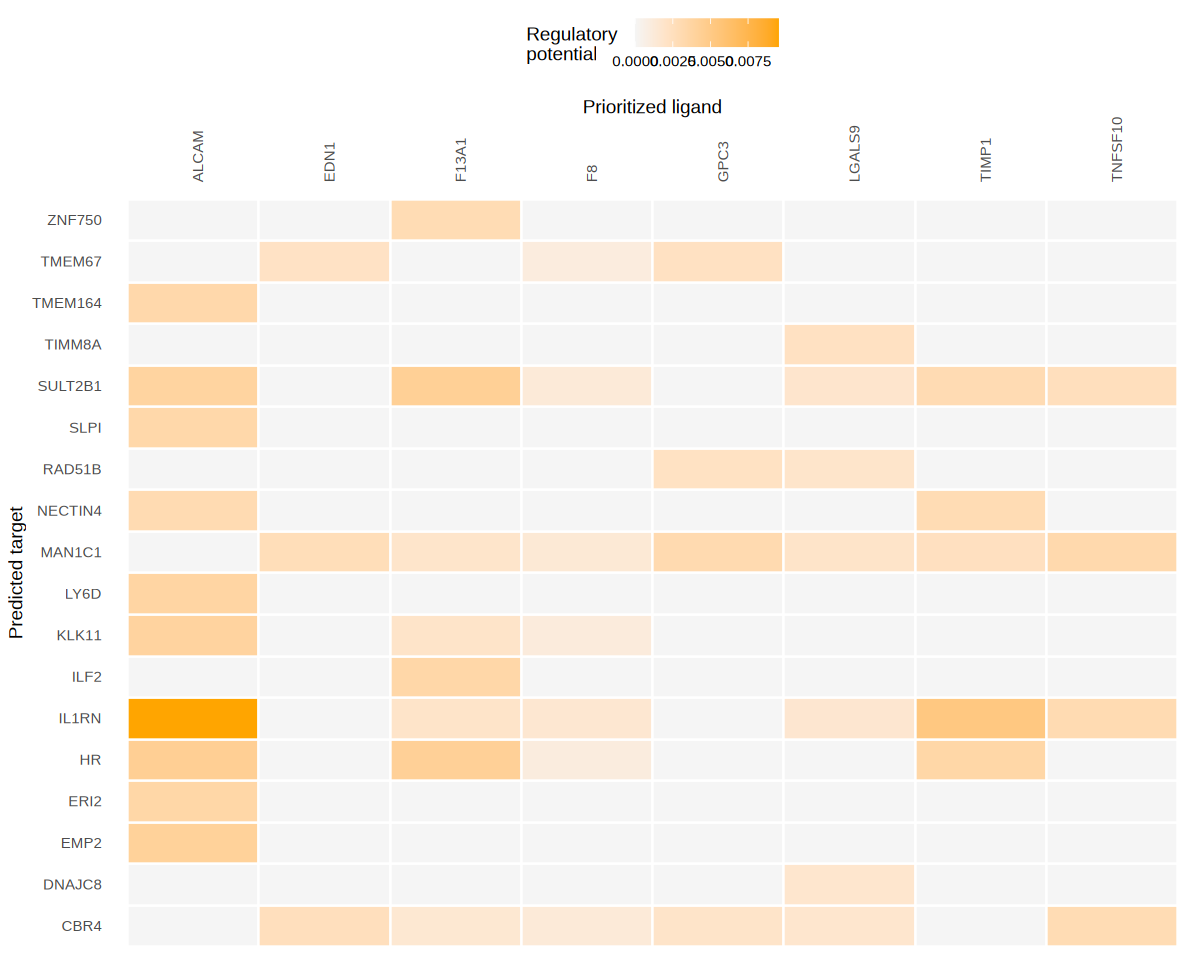

In [24]:
options(repr.plot.width = 10, repr.plot.height = 8)

native_mn_receiver <- "basal"
native_mn_ligands <- ctx_prio %>%
    filter(group == IDENT_1, receiver == native_mn_receiver) %>%
    arrange(desc(prioritization_score)) %>%
    distinct(ligand) %>%
    slice_head(n = 8) %>%
    pull(ligand)

mn_heatmap_links <- pkg_mn_ctx$multinichenet_output$ligand_activities_targets_DEgenes$ligand_activities %>%
    filter(
        contrast == paste0(IDENT_1, "-", IDENT_2),
        receiver == native_mn_receiver,
        ligand %in% native_mn_ligands
    ) %>%
    group_by(ligand) %>%
    slice_max(order_by = ligand_target_weight, n = 10, with_ties = FALSE) %>%
    ungroup()

cat("Native MultiNicheNet heatmap links:", nrow(mn_heatmap_links), "\n")

if (nrow(mn_heatmap_links) > 0) {
    mn_heatmap_xtabs <- stats::xtabs(ligand_target_weight ~ target + ligand, data = mn_heatmap_links)
    mn_heatmap_matrix <- matrix(
        as.numeric(mn_heatmap_xtabs),
        nrow = nrow(mn_heatmap_xtabs),
        dimnames = dimnames(mn_heatmap_xtabs)
    )
    suppressWarnings(print(nichenetr::make_heatmap_ggplot(
        mn_heatmap_matrix,
        y_name = "Predicted target",
        x_name = "Prioritized ligand",
        legend_title = "Regulatory\npotential",
        color = "orange",
        x_axis_position = "top"
    )))
}
